# Intro
The objective of this study is to create a classification model to classify   12-lead ECG records of 10 seconds length between this classes:

|Records	|Superclass	|Description|
|----------|:-------------:|------:|
|9517	 |  NORM | Normal ECG |
|5473	 |  MI	 |  Myocardial  Infarction |
| 5237 |	STTC |	ST/T Change |
| 4901 |	CD   |	Conduction Disturbance |
| 2649 |	HYP  |	Hypertrophy |


> [!NOTE] Multi-label classification
> Note that this a record can belong to more than one class. For example, a record can be classified as MI and CD at the same time. 

# Dataset
Some basic info about the dataset:
[Dataset](https://physionet.org/content/ptb-xl/1.0.2/)
1. Standard set of 12 leads
2. For most records also the heart’s axis (heart_axis) and infarction stadium (infarction_stadium1 and infarction_stadium2, if present) were extracted.
4. A large fraction of the records was validated by a second cardiologist.
5. All records were validated by a technical expert focusing mainly on signal characteristics.(Should be low noise and good signal quality)

6. ECGs and patients are identified by unique identifiers (ecg_id and patient_id).

7. General Metadata: demographic and recording metadata such as age, sex, height, weight, nurse, site, device and recording_date

8. Signal Metadata: signal quality such as noise (static_noise and burst_noise), baseline drifts (baseline_drift) and other artifacts such as electrodes_problems. We also provide extra_beats for counting extra systoles and pacemaker for signal patterns indicating an active pacemaker.

9. Cross-validation Folds: Folds 1-8 as training set, fold 9 as validation set and fold 10 as test set.

# Metadata
First thing we will do is explore the metadata of the dataset, with emphasis on reported superclasses, as they will be our target classes.

In [1]:
import os
import pandas as pd
import numpy as np
import wfdb
import ast
from tqdm import tqdm
path = '../../data/ptbl/'
# load and convert annotation data
Y = pd.read_csv(path+'ptbxl_database.csv', index_col='ecg_id')
Y.scp_codes = Y.scp_codes.apply(lambda x: ast.literal_eval(x))
# Load scp_statements.csv for diagnostic aggregation
agg_df = pd.read_csv(path+'scp_statements.csv', index_col=0)
agg_df = agg_df[agg_df.diagnostic == 1]


def aggregate_diagnostic(y_dic):
    tmp = []
    for key in y_dic.keys():
        if key in agg_df.index:
            tmp.append(agg_df.loc[key].diagnostic_class)
    return list(set(tmp))


# Apply diagnostic superclass
Y['diagnostic_superclass'] = Y.scp_codes.apply(aggregate_diagnostic)

In [2]:
Y.describe(include='all')

,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr,diagnostic_superclass
count,21799.000000,21799.000000,21799.000000,6974.000000,9421.000000,20326.000000,21782.000000,21799,21799,21799,...,1598,3260,613,30,1949,291,21799.000000,21799,21799,21799
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11,21795,9887,...,317,124,103,14,128,4,NaN,21799,21799,26
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CS100 3,1992-02-06 11:47:42,sinus rhythm. normal ecg.,...,", V6",", I-AVR,",alles,V6,1ES,"ja, pacemaker",NaN,records100/00000/00001_lr,records500/00000/00001_hr,[NORM]
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6140,2,1734,...,221,953,140,8,405,285,NaN,1,1,9069
mean,11250.156521,62.769301,0.479150,166.702323,70.995223,2.291745,1.544945,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,5.503005,NaN,NaN,NaN
std,6235.026404,32.308813,0.499577,10.867321,15.878803,3.254033,4.172883,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2.874948,NaN,NaN,NaN
min,302.000000,2.000000,0.000000,6.000000,5.000000,0.000000,0.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN
25%,5974.500000,50.000000,0.000000,160.000000,60.000000,0.000000,0.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,NaN,NaN
50%,11419.000000,62.000000,0.000000,166.000000,70.000000,1.000000,1.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,6.000000,NaN,NaN,NaN
75%,16607.500000,72.000000,1.000000,174.000000,80.000000,3.000000,2.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,8.000000,NaN,NaN,NaN


## Target Classes

Check to see the distribution of the target classes and see how much overlap there is

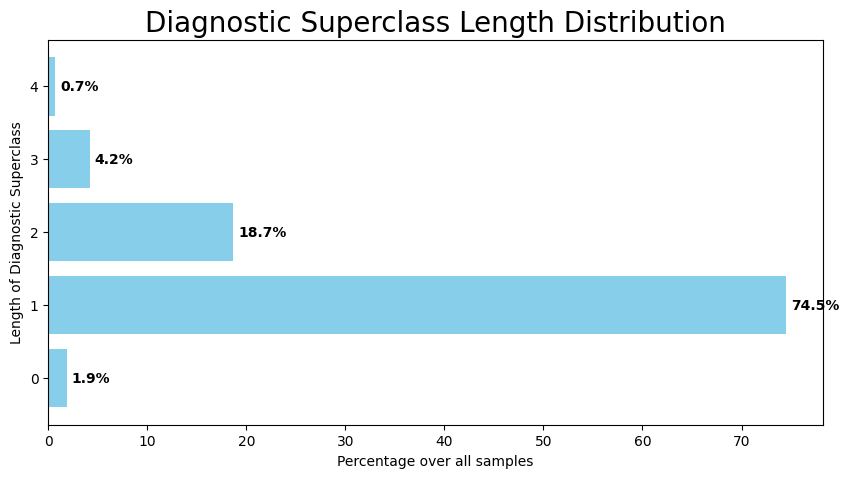

Number of empty diagnostics:  411
Number of multiple diagnostics:  5144


In [3]:
import matplotlib.pyplot as plt
# Calculate the length of each diagnostic superclass
lengths = Y['diagnostic_superclass'].apply(len)

# Calculate the value counts for each length
vc = lengths.value_counts().sort_index()

# Calculate the percentage
percentages = vc.values / vc.values.sum() * 100

# Create the plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(vc.index, percentages, color='skyblue')
# Add title and labels
ax.set_title("Diagnostic Superclass Length Distribution", fontsize=20)
ax.set_xlabel("Percentage over all samples")
ax.set_ylabel("Length of Diagnostic Superclass")

# Add percentage labels next to the bars
for i in range(len(percentages)):
    ax.text(percentages[i] + 0.5, vc.index[i], f"{percentages[i]:.1f}%", va='center', ha='left', fontweight='bold')

# Display the plot
plt.show()
# Check index of the diagnostics that dont have any superclass
empty_diagnotics_index = ([index for index in Y.index if len(Y['diagnostic_superclass'].loc[index]) == 0])
# Check for the ones with 2 or more superclasses
multiple_diagnotics_index = ([index for index in Y.index if len(Y['diagnostic_superclass'].loc[index]) >= 2])
print('Number of empty diagnostics: ', len(empty_diagnotics_index))
print('Number of multiple diagnostics: ', len(multiple_diagnotics_index))


There are some records that dont have a superclass, we will remove them from the dataset
In addition, we we can see that there are some records that have multiple superclasses, therefore we cant use a softmax activation function in the output layer of our model. Each class is independent of the others.

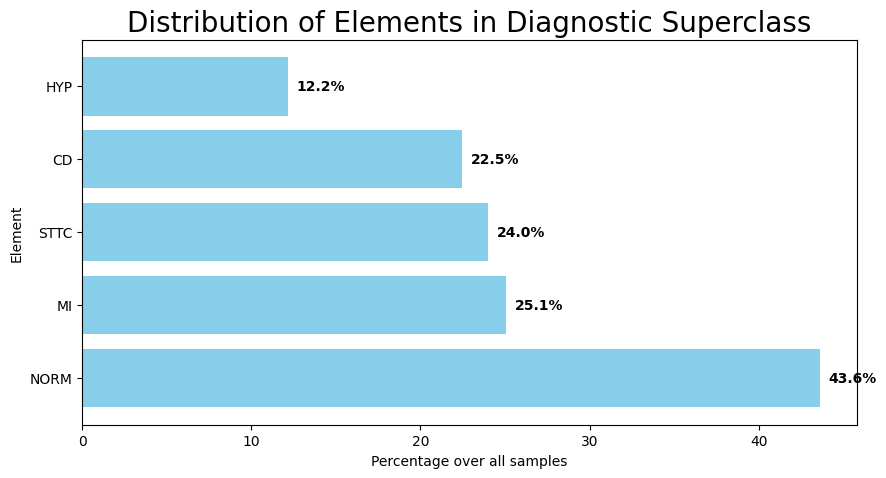

In [4]:
flat_list = [item for sublist in Y['diagnostic_superclass'] for item in sublist]
# total number of samples in the dataset 
total_samples = len(Y)
# Convert to a pandas Series and calculate value counts
element_counts = pd.Series(flat_list).value_counts()

# Calculate the percentage
percentages = element_counts.values / total_samples * 100


# Create the plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(element_counts.index, percentages, color='skyblue')

# Add title and labels
ax.set_title("Distribution of Elements in Diagnostic Superclass", fontsize=20)
ax.set_xlabel("Percentage over all samples")
ax.set_ylabel("Element")

# Add percentage labels next to the bars
for i in range(len(percentages)):
    ax.text(percentages[i] + 0.5, element_counts.index[i], f"{percentages[i]:.1f}%", va='center', ha='left', fontweight='bold')

# Display the plot
plt.show()

We can see the that the classes are imbalanced, with the NORM class being the most balanced, and the HYP class being the least balanced. We will need to take this into account when training our model. Given that we can have multiple classes per record data augmentation will be difficult, therefore we should consider using loss weights to account for the class imbalance.


In [5]:
# We will see for each length of the diagnostic superclass, what is the distribution of elements
import pandas as pd
import matplotlib.pyplot as plt

# Calculate the length of each list
Y['length'] = Y['diagnostic_superclass'].apply(len)

# Initialize a dictionary to hold the counts of each element by list length
element_distribution = {}

# Iterate over each row in the DataFrame
for _, row in Y.iterrows():
    length = row['length']
    elements = row['diagnostic_superclass']
    
    if length not in element_distribution:
        element_distribution[length] = []
    
    element_distribution[length].extend(elements)

# Convert the distribution dictionary to a DataFrame for easier analysis
distribution_df = pd.DataFrame([
    (length, element) for length, elements in element_distribution.items() for element in elements
], columns=['Length', 'Element'])

# Calculate the counts of each element by list length
counts = distribution_df.groupby(['Length', 'Element']).size().unstack(fill_value=0)

# Calculate the percentages
percentages = counts.div(counts.sum(axis=1), axis=0) * 100

percentages

Element,CD,HYP,MI,NORM,STTC
Length,,,,,
1,10.514652,3.293524,15.587294,55.829845,14.774686
2,30.420354,15.560472,25.553097,5.371190,23.094887
3,20.239391,25.063475,25.426188,0.253899,29.017048
4,25.000000,25.000000,25.000000,0.159236,24.840764


We can see that most of the times when the the diagnosis is NORM there are no other classes present, yet it cannot be considered as equivalent to the absence of the other classes, as there are some records that have NORM as a superclass and another superclass as well. Therefore, we will consider the NORM class as a superclass on its own, and not as the absence of the other classes.

### Conclusion
We will have to use a multi-label classification model, with 5 classes, multiple classes can be present in a record, the classes are imbalanced, and we will have to use loss postiive weights to account for this.

## Other Metadata
We will explore if any of the other metadata can be used to improve the model performance

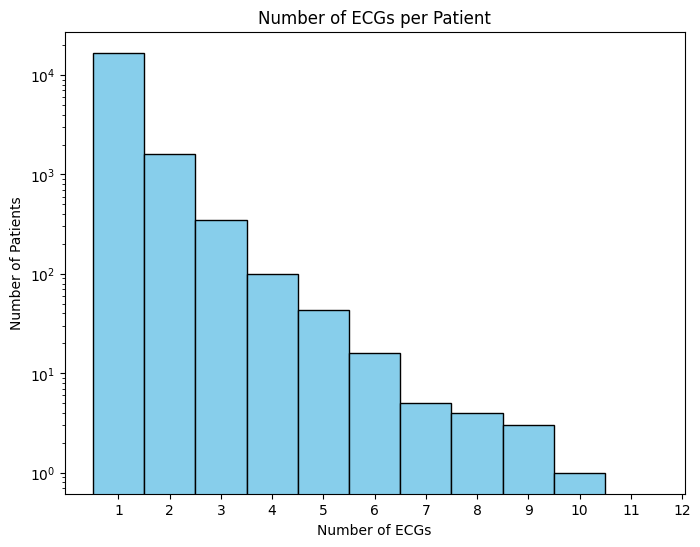

In [6]:
ecg_per_patient = Y.groupby("patient_id").size()

plt.figure(figsize=(8, 6))
# scale is set to log to better visualize the distribution
plt.hist(ecg_per_patient, bins=range(1, 13), color='skyblue', edgecolor='black', align='left', log=True)
plt.title("Number of ECGs per Patient")
plt.xlabel("Number of ECGs")
plt.ylabel("Number of Patients")
plt.xticks(range(1, 13))
plt.show()


In [7]:
# Explode the diagnostic superclass list to have one row per element
Y_exploded = Y.explode('diagnostic_superclass').reset_index(drop=True)

# has pacemaker boolean
Y_exploded['has_pacemaker'] = Y_exploded['pacemaker'].apply(lambda x: 0 if pd.isnull(x) else 1)
# has infarction_stadium1 boolean
Y_exploded['has_infarction_stadium1'] = Y_exploded['infarction_stadium1'].apply(lambda x: 0 if pd.isnull(x) else 1)
# has infarction_stadium2 boolean
Y_exploded['has_infarction_stadium2'] = Y_exploded['infarction_stadium2'].apply(lambda x: 0 if pd.isnull(x) else 1)
# has extra_beats boolean
Y_exploded['has_extra_beats'] = Y_exploded['extra_beats'].apply(lambda x: 0 if pd.isnull(x) else 1)
# has baseline_drift boolean
Y_exploded['has_baseline_drift'] = Y_exploded['baseline_drift'].apply(lambda x: 0 if pd.isnull(x) else 1)
# normal normal_heart_axis
Y_exploded['normal_heart_axis'] = Y_exploded['heart_axis'].apply(lambda x: 1 if pd.isnull(x) else 0)

# diagnostic superclass as categorical numbers
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
Y_exploded['diagnostic_superclass2'] = le.fit_transform(Y_exploded['diagnostic_superclass'])


<Axes: >

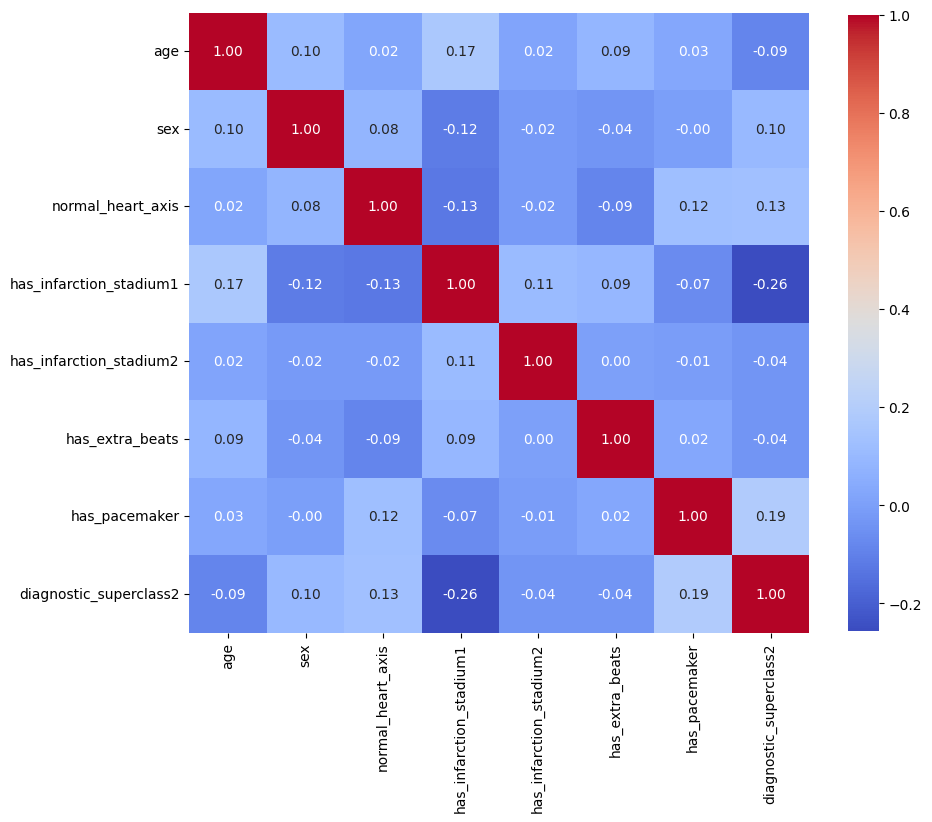

In [8]:
import seaborn as sns
correlation_matrix = Y_exploded[
    [
        "age",
        "sex",
        "normal_heart_axis",
        "has_infarction_stadium1",
        "has_infarction_stadium2",
        "has_extra_beats",
        "has_pacemaker",
        "diagnostic_superclass2"

    ]
].corr()

# Create the plot and set the figure size
plt.figure(figsize=(10, 10))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8})

In [9]:
Y.describe(include='all')

,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr,diagnostic_superclass,length
count,21799.000000,21799.000000,21799.000000,6974.000000,9421.000000,20326.000000,21782.000000,21799,21799,21799,...,3260,613,30,1949,291,21799.000000,21799,21799,21799,21799.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11,21795,9887,...,124,103,14,128,4,NaN,21799,21799,26,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CS100 3,1992-02-06 11:47:42,sinus rhythm. normal ecg.,...,", I-AVR,",alles,V6,1ES,"ja, pacemaker",NaN,records100/00000/00001_lr,records500/00000/00001_hr,[NORM],NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6140,2,1734,...,953,140,8,405,285,NaN,1,1,9069,NaN
mean,11250.156521,62.769301,0.479150,166.702323,70.995223,2.291745,1.544945,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,5.503005,NaN,NaN,NaN,1.273682
std,6235.026404,32.308813,0.499577,10.867321,15.878803,3.254033,4.172883,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,2.874948,NaN,NaN,NaN,0.603352
min,302.000000,2.000000,0.000000,6.000000,5.000000,0.000000,0.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,0.000000
25%,5974.500000,50.000000,0.000000,160.000000,60.000000,0.000000,0.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,NaN,NaN,1.000000
50%,11419.000000,62.000000,0.000000,166.000000,70.000000,1.000000,1.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,6.000000,NaN,NaN,NaN,1.000000
75%,16607.500000,72.000000,1.000000,174.000000,80.000000,3.000000,2.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,8.000000,NaN,NaN,NaN,1.000000


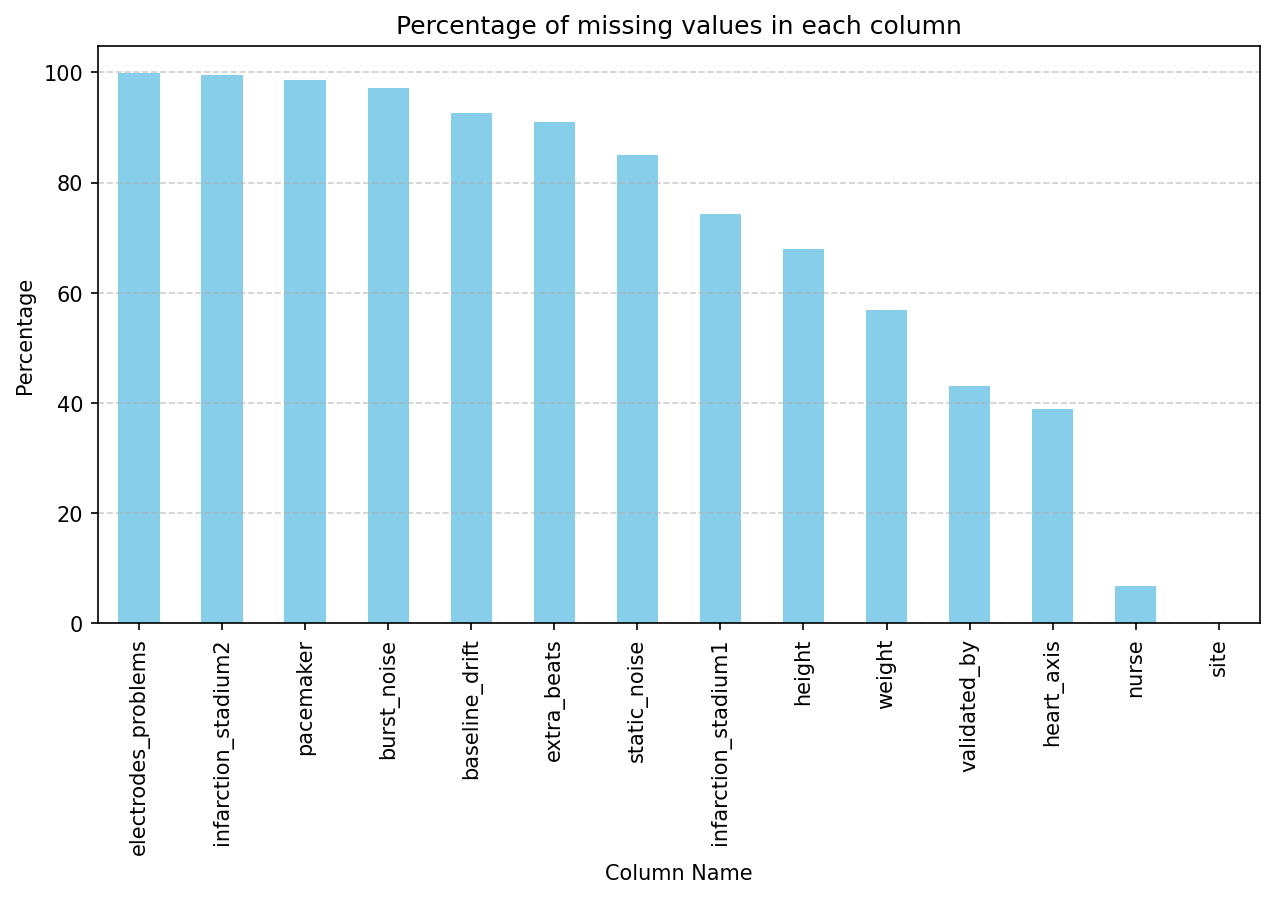

In [10]:
# Calculate percentage of missing values
null_values = Y.isnull().sum().sort_values(ascending=False)
percent = (Y.isnull().sum() / len(Y)) * 100
percent = percent[percent > 0].sort_values(ascending=False)

plt.figure(figsize=(10,5 ), dpi=150)
ax = percent.plot(kind='bar', color='skyblue')

plt.grid(axis='y', linestyle='--', alpha=0.6)
# Set axis labels
plt.xlabel('Column Name')
plt.ylabel('Percentage')
plt.title('Percentage of missing values in each column')
# Rotate x-axis labels
plt.xticks(rotation=90)

# Display the plot
plt.show()


height and weight are missing for a lot of records, and they are not very useful for the classification task, so we will not use them.
Lets now do a quick exploration of the metadata to see if they are statistically significant for the classification task.

In [11]:
import pandas as pd
import scipy.stats as stats
import numpy as np



variables = ['normal_heart_axis','has_baseline_drift','has_pacemaker', 'has_infarction_stadium1', 'has_extra_beats', 'has_infarction_stadium2', 'age', 'heart_axis', "static_noise",
             'sex','heart_axis',"infarction_stadium1",	"infarction_stadium2", 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker']
# Create a contingency table
for variable in variables:
    contingency_table = pd.crosstab(Y_exploded[variable], Y_exploded['diagnostic_superclass'])

    # Chi-Square Test
    chi2, p, dof, ex = stats.chi2_contingency(contingency_table)

    # Calculate Cramér's V
    n = contingency_table.sum().sum()
    min_dim = min(contingency_table.shape) - 1
    cramers_v = np.sqrt((chi2/n) / min_dim)

    print(f"{variable}: Chi-Square Statistic: {chi2}, p-value: {p}, Cramér's V: {cramers_v}")

normal_heart_axis: Chi-Square Statistic: 795.3499900957129, p-value: 7.808418061092801e-171, Cramér's V: 0.16925063279269592
has_baseline_drift: Chi-Square Statistic: 22.37691690059494, p-value: 0.0001686021138200002, Cramér's V: 0.028389077841700684
has_pacemaker: Chi-Square Statistic: 2.00923530204364, p-value: 0.734060149488484, Cramér's V: 0.008506806634852324
has_infarction_stadium1: Chi-Square Statistic: 15448.179931301831, p-value: 0.0, Cramér's V: 0.7459158244190429
has_extra_beats: Chi-Square Statistic: 437.0491539107655, p-value: 2.73820032036762e-93, Cramér's V: 0.12546318346660157
has_infarction_stadium2: Chi-Square Statistic: 234.70281846736108, p-value: 1.282637578837514e-49, Cramér's V: 0.09194123086077219
age: Chi-Square Statistic: 5207.975932500722, p-value: 0.0, Cramér's V: 0.216548734319785
heart_axis: Chi-Square Statistic: 3327.2121063861923, p-value: 0.0, Cramér's V: 0.21829203096126865
static_noise: Chi-Square Statistic: 533.1212595307227, p-value: 0.0773360832481

Given the p-values, we can see that variables such as age, heart_axis, sex, and whether it was marked with any typeof infractions or extrabeats are statistically significant for the classification task. We will use these variables in our model.
All these selected variables but age and gender actually comefrom the ECG signal annotations, so it can be debatable if they need to be included in the model or not. We will include them in the model, as they are part of the metadata of the dataset, and they are statistically significant for the classification task, but it should also be tested if the model performs worse without them, as annotations can be noisy and time consuming to obtain. 

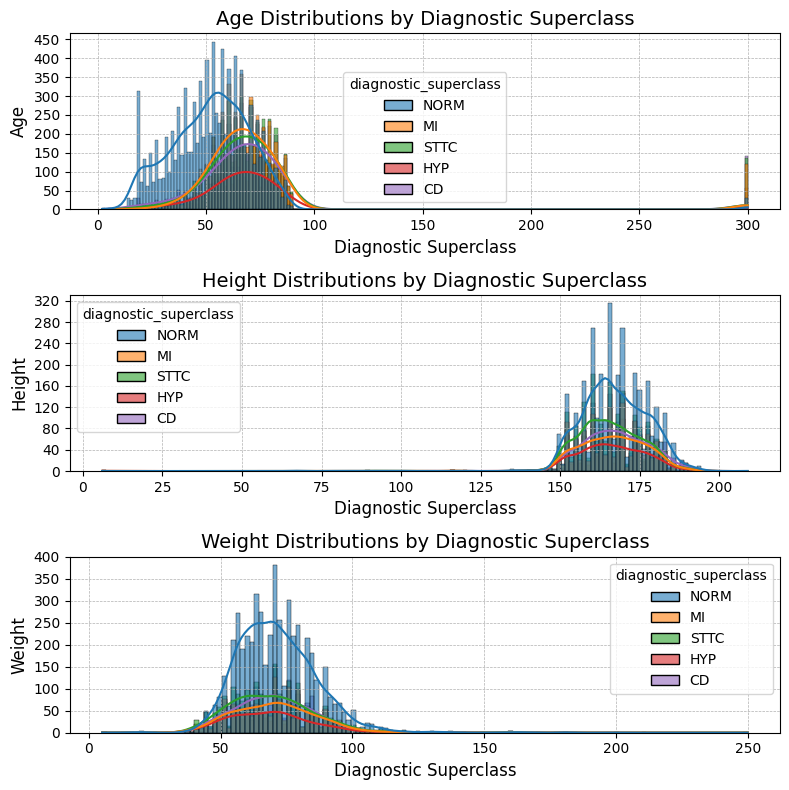

In [12]:
import seaborn as sns
variables_to_plot = ['age', 'height', 'weight']

# duplicate each row for each value in the list of superclass
Y_exploded = Y.explode('diagnostic_superclass').reset_index(drop=True)

fig, axes = plt.subplots(len(variables_to_plot), 1, figsize=(8, 8))  # Adjust the figsize for better spacing

for i, variable in enumerate(variables_to_plot):
    axes[i].set_title(f'{variable} Distributions of Different Superclass')
    sns.histplot(Y_exploded , x=variable, hue='diagnostic_superclass', ax=axes[i], kde=True, alpha=0.6)
    # sns.violinplot(data=Y_exploded, x='diagnostic_superclass', y=variable, ax=axes[i],  alpha=0.6)
    # show tight grid with double the number of ticks
    axes[i].grid(True, which='both', linestyle='--', linewidth=0.5)

    # Set title and labels
    axes[i].set_title(f'{variable.capitalize()} Distributions by Diagnostic Superclass', fontsize=14)
    axes[i].set_xlabel('Diagnostic Superclass', fontsize=12)
    axes[i].set_ylabel(variable.capitalize(), fontsize=12)
    axes[i].yaxis.set_major_locator(plt.MaxNLocator(10))

plt.tight_layout()
plt.show()

### Conclusion
We will use the following metadata in our model:
- age (we have to filter the outliers)
- sex

and ecg related metadata:
- heart_axis
- has_infraction_stadium1
- has_infraction_stadium2
- has_extrabeats
- has_baseline_drift

Presence of noise(static noise, burst_noise, electrode_problems) does not seem to be statistically significant for the classification task, so I wont need to filter the records based on the presence of noise, we have also been told that the records have been validated by a technical expert focusing mainly on signal characteristics, so we can assume that the records are of good quality. We could do a quality check with neurokit2, but it would take a lot of time in my computer, so I will skip this step.

# ECG Signals

In [13]:
# Keep only the records that can be used for training
Y = Y[Y['diagnostic_superclass'].apply(len) > 0].reset_index(drop=True)
Y = Y[Y['age'] < 100].reset_index(drop=True)

In [14]:

def load_raw_data(df, sampling_rate, path):
    if sampling_rate == 100:
        data = [wfdb.rdsamp(path+f) for f in tqdm(df.filename_lr)]
    else:
        data = [wfdb.rdsamp(path+f) for f in tqdm(df.filename_hr)]
    data = np.array([signal for signal, meta in data])
    return data

sampling_rate = 100 #500 will make the parameter count explode, would have to extract features from the raw data in that case

X = load_raw_data(Y, sampling_rate, path) # (patient_id, len, lead_num) 


100%|██████████| 21103/21103 [07:24<00:00, 47.51it/s]


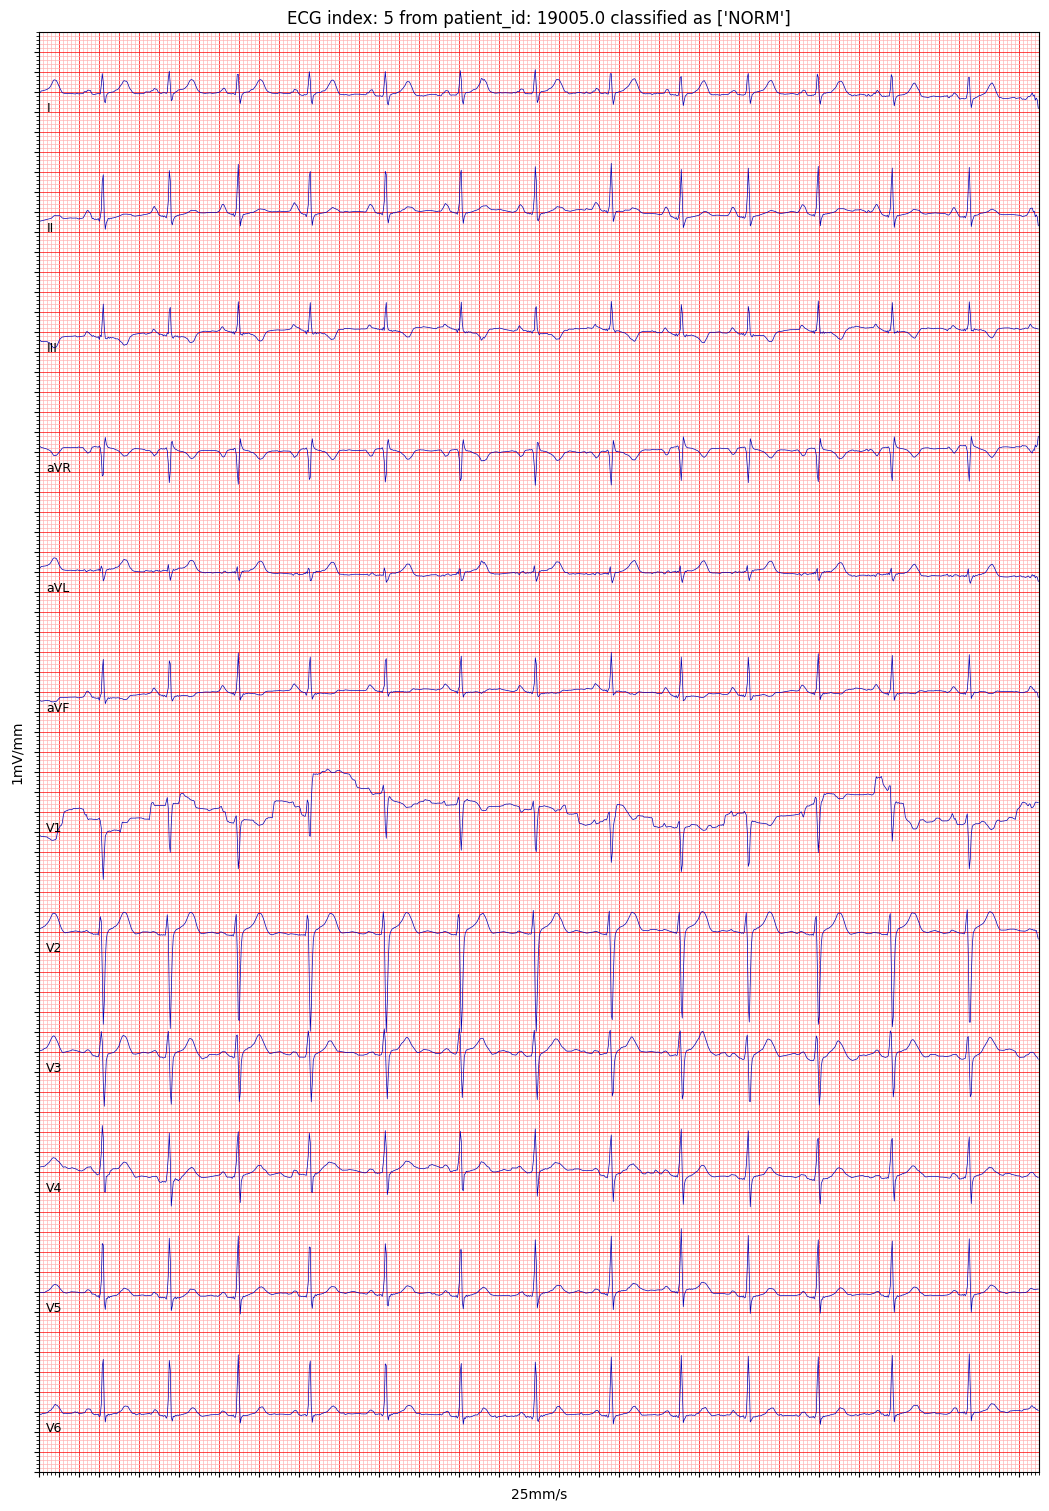

In [15]:
import ecg_plot
def plot_12lead(X,y, ecg_index):
    Xt = X[ecg_index, :].T
    y.loc
    ecg_plot.plot(Xt, sample_rate=100, title="", columns=1,row_height=6)
    # add title to the x axis
    plt.title(f'ECG index: {ecg_index} from patient_id: {y.loc[ecg_index].patient_id} classified as {y.loc[ecg_index].diagnostic_superclass}')

    fig = plt.gcf()  # Get the current figure
    axes = fig.get_axes()  # Get the list of axes in the figure
    for ax in axes:
        ax.yaxis.set_ticklabels([])  # Hide the tick labels (numbers)
        ax.grid(True)  # Ensure grid is visible
        ax.xaxis.set_ticklabels([])
        plt.xlabel('25mm/s')
        plt.ylabel('1mV/mm')

    ecg_plot.show()
index = 5
plot_12lead(X,Y, index)

# Model
We will use a multi-label classification model, with 5 classes. We will use the metadata as well as the raw ECG signals as input to the model. We will use an LSTM model, although other arquitectures should be tested as well. 

Get all the features that were extracted deemed useful for the classification task, and then train the model.

In [16]:
import torch
# Apply the features we saw in the data exploration
# has pacemaker boolean
Y['has_pacemaker'] = Y['pacemaker'].apply(lambda x: 0 if pd.isnull(x) else 1)
# has infarction_stadium1 boolean
Y['has_infarction_stadium1'] = Y['infarction_stadium1'].apply(lambda x: 0 if pd.isnull(x) else 1)
# has infarction_stadium2 boolean
Y['has_infarction_stadium2'] = Y['infarction_stadium2'].apply(lambda x: 0 if pd.isnull(x) else 1)
# has extra_beats boolean
Y['has_extra_beats'] = Y['extra_beats'].apply(lambda x: 0 if pd.isnull(x) else 1)
# has baseline_drift boolean
Y['has_baseline_drift'] = Y['baseline_drift'].apply(lambda x: 0 if pd.isnull(x) else 1)
# normal normal_heart_axis
Y['normal_heart_axis'] = Y['heart_axis'].apply(lambda x: 1 if pd.isnull(x) else 0)

from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
mlb = MultiLabelBinarizer()
labels = mlb.fit_transform(Y.diagnostic_superclass)
# Get the name of the classes
class_names = mlb.classes_
class_names


print(X.shape)
print(labels.shape)

(21103, 1000, 12)
(21103, 5)


In [17]:
# Create the tensor of encoded data
encoded_data = torch.zeros(len(Y), 7, dtype=torch.float32)
encoded_data[:, 0] = torch.tensor(Y['age'].values, dtype=torch.float32)
heart_axis = Y['heart_axis'].apply(lambda x: {'LAD': 0, 'RAD': 1, 'ALAD': 2, 'AXR': 3, 'MID': 4, 'ARAD': 5, 'AXL': 6, 'SAG': 7}.get(x, 8))
encoded_data[:, 1] = torch.tensor(heart_axis.values, dtype=torch.float32)
encoded_data[:, 2] = torch.tensor(Y['has_infarction_stadium1'].apply(lambda x: 0 if pd.isnull(x) else 1).values, dtype=torch.float32)
encoded_data[:, 3] = torch.tensor(Y['has_infarction_stadium2'].apply(lambda x: 0 if pd.isnull(x) else 1).values, dtype=torch.float32)
encoded_data[:, 4] = torch.tensor(Y['has_extra_beats'].apply(lambda x: 0 if pd.isnull(x) else 1).values, dtype=torch.float32)
encoded_data[:, 5] = torch.tensor(Y['has_baseline_drift'].apply(lambda x: 0 if pd.isnull(x) else 1).values, dtype=torch.float32)
encoded_data[:, 6] = torch.tensor(Y['sex'].values)

As the dataset is imbalanced, we will use loss weights to account for this, as other techniques such as data augmentation are not easily possible given that we can have multiple classes per record. 

In [18]:

from sklearn.utils.class_weight import compute_class_weight
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class_weights = []
for i in range(labels.shape[1]):  # For each class
    # Compute class weight for class i
    weights = compute_class_weight(class_weight='balanced', classes=[0, 1.], y=labels[:, i])
    class_weights.append(weights[1])  # We're interested in the weight for the "positive" class

class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

### Dataloader

We will use a standard LSTM dataloader. All sequences are of the same length, so we dont need to pad them.
Metadata is normalized and added as extra features to the ECG signals.
I added the ability to do folds to create more samples for training, as the timeseries migh be too long for the model to effectively learn from them.


In [19]:
import torch
from torch.utils.data import Dataset, DataLoader
import pytorch_lightning as pl
import numpy as np


import torch

def split_and_stack(tensor, split_dim, num_splits):
    """
    Splits a tensor along the specified dimension and stacks the resulting parts.

    Parameters:
    tensor (torch.Tensor): The input tensor.
    split_dim (int): The dimension to split.
    num_splits (int): The number of splits to make.

    Returns:
    torch.Tensor: The resulting tensor after splitting and stacking.
    """
    # Get the shape of the tensor
    tensor_shape = list(tensor.shape)
    
    # Ensure the dimension can be split evenly
    assert tensor_shape[split_dim] % num_splits == 0, "Dimension size must be divisible by num_splits"
    
    # Calculate the new size of the dimension that will be split
    new_size = tensor_shape[split_dim] // num_splits
    
    # Reshape the tensor to split the specified dimension
    tensor_reshaped = tensor.view(*tensor_shape[:split_dim], num_splits, new_size, *tensor_shape[split_dim+1:])
    
    # Permute the tensor to bring the new dimension (num_splits) to the front
    permute_order = [split_dim, split_dim + 1] + list(range(0, split_dim)) + list(range(split_dim + 2, len(tensor_reshaped.shape)))
    tensor_permuted = tensor_reshaped.permute(0, 2, 1, 3)
    
    # Reshape the tensor to collapse the split dimension and the original first dimension
    final_shape = [-1, new_size] + tensor_shape[split_dim + 1:]
    final_tensor = tensor_permuted.contiguous().view(final_shape)
    
    return final_tensor

class ECGDataset(Dataset):
    def __init__(self, ecg_data, metadata, labels):
        """
        Args:
            ecg_data (numpy.ndarray): ECG signal data with shape (num_samples, num_leads, sequence_length)
            metadata (numpy.ndarray): Metadata with shape (num_samples, num_metadata_features)
            labels (numpy.ndarray): Labels for 4 tasks with shape (num_samples, 4)
        """
        self.ecg_data = ecg_data
        self.metadata = metadata
        self.labels = torch.tensor(labels, dtype=torch.float32)
        self.x_metadata = torch.tensor(metadata, dtype=torch.double)
        self.x_metadata = self.x_metadata.unsqueeze(1)
        # copy for seq length
        self.x_metadata = self.x_metadata.repeat(1, ecg_data.shape[1], 1)

    def __len__(self):
        return len(self.ecg_data)

    def __getitem__(self, idx):
        # self.metadata.shape torch.Size([32, 7])
        # make it [32, 1000, 7]
        return self.ecg_data[idx], self.x_metadata[idx], self.labels[idx]


class ECGDataModule(pl.LightningDataModule):
    def __init__(self, ecg_data, metadata, labels,Y,strat_fold, batch_size=32,n_folds =1):
        super().__init__()
        self.ecg_data = ecg_data
        self.metadata = metadata
        self.labels = labels
        self.batch_size = batch_size
        self.Y = Y
        self.strat_fold = strat_fold
        self.n_folds = n_folds

    def setup(self, stage=None):
        # Standarize tabular data
        scaler = StandardScaler()
        self.metadata = scaler.fit_transform(self.metadata)

        # Split the data into train, test, and validation sets
        test_fold = 10
        val_fold = 9
        # Create masks for the train, test, and validation sets
        train_mask = (self.strat_fold != test_fold) & (self.strat_fold != val_fold)
        test_mask = self.strat_fold == test_fold
        val_mask = self.strat_fold == val_fold
        X_train, y_train, xm_train = self.ecg_data[train_mask], self.labels[train_mask], self.metadata[train_mask]
        if self.n_folds >1 :
            X_train = split_and_stack(torch.tensor(X_train),1,self.n_folds)
            y_train = torch.tensor(y_train).repeat_interleave(self.n_folds,dim=0)
            xm_train = torch.tensor(xm_train).repeat_interleave(self.n_folds,dim=0)
        X_test, y_test, xm_test = self.ecg_data[test_mask], self.labels[test_mask], self.metadata[test_mask]
        X_val, y_val, xm_val = self.ecg_data[val_mask], self.labels[val_mask], self.metadata[val_mask]
        

        # Create ECGDataset object

        self.train_dataset = ECGDataset(X_train, xm_train, y_train)
        self.test_dataset = ECGDataset(X_test, xm_test, y_test)
        self.val_dataset = ECGDataset(X_val, xm_val, y_val)

    def train_dataloader(self):
        # use as many CPU cores as available
        return DataLoader(self.train_dataset, batch_size=self.batch_size, shuffle=True)

    def val_dataloader(self):
        return DataLoader(self.val_dataset, batch_size=self.batch_size, shuffle=False)

    def test_dataloader(self):
        return DataLoader(self.test_dataset, batch_size=self.batch_size, shuffle=False)

# get the data
datamodule = ECGDataModule(X, encoded_data, labels, encoded_data, Y.strat_fold,n_folds=4)
datamodule.setup()
train_loader = datamodule.train_dataloader()

# Get a single batch
x,metadata, y = next(iter(train_loader))
print(x.shape)
print(metadata.shape)
print(y.shape)


c:\Users\Fran.DESKTOP-VD7PKMI\mambaforge\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Fran.DESKTOP-VD7PKMI\AppData\Local\Temp\ipykernel_15436\1059357004.py:53: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.labels = torch.tensor(labels, dtype=torch.float32)
C:\Users\Fran.DESKTOP-VD7PKMI\AppData\Local\Temp\ipykernel_15436\1059357004.py:54: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.x_metadata = torch.tensor(metadata, dtype=torch.double)


torch.Size([32, 250, 12])
torch.Size([32, 250, 7])
torch.Size([32, 5])


# Model
The model is a standard LSTM model, many metrics are logged.
We use a weighted binary crossentropy loss function, as the classes are imbalanced ADAM optimizer is used, and a learning rate scheduler is used to reduce the learning rate when the validation loss stops decreasing.

In [20]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import pytorch_lightning as pl
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, roc_auc_score, hamming_loss

class LSTMModel(pl.LightningModule):
    def __init__(self, input_size, hidden_size, num_layers,pos_weight, num_classes, learning_rate=0.001, dropout_rate=0.2):
        super().__init__()
        self.save_hyperparameters()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=dropout_rate if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout_rate)
        self.fc = nn.Linear(hidden_size, num_classes)
        self.criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        self.hparams.learning_rate = learning_rate

        self.test_step_outputs = []

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.dropout(out[:, -1, :])
        return self.fc(out)

    def training_step(self, batch, batch_idx):
        x, metadata, y = batch
        x = torch.cat((x, metadata), dim=2)
        y_hat = self(x.float())
        loss = self.criterion(y_hat, y)
        self.log('train_loss', loss)
        preds = torch.sigmoid(y_hat)
        f1 = f1_score(y.cpu().detach().numpy(), (preds.cpu().detach().numpy() > 0.5).astype(int), average='micro')
        self.log('train_f1', f1)
        return loss

    def validation_step(self, batch, batch_idx):
        x, metadata, y = batch
        x = torch.cat((x, metadata), dim=2)
        y_hat = self(x.float())
        loss = self.criterion(y_hat, y)
        self.log('val_loss', loss)
        # Calculate metrics
        preds = (torch.sigmoid(y_hat) > 0.5).int()
        f1 = f1_score(y.cpu().detach().numpy(), preds.cpu().detach().numpy(), average='micro')
        self.log('val_f1', f1)
        return loss

    def test_step(self, batch, batch_idx):
        x, metadata, y = batch
        x = torch.cat((x, metadata), dim=2)

        y_hat = self(x.float())
        loss = self.criterion(y_hat, y)
        preds = torch.sigmoid(y_hat)
        self.log('test_loss', loss)
        self.test_step_outputs.append({'preds': preds, 'target': y})
        return loss

    def on_test_epoch_end(self):
        # Gather predictions and targets from all test batches
        preds = torch.cat([x['preds'] for x in self.test_step_outputs])
        targets = torch.cat([x['target'] for x in self.test_step_outputs])
        
        # Convert to numpy arrays
        preds = preds.cpu().numpy()
        targets = targets.cpu().numpy()
        
        # Apply threshold to get binary predictions
        preds_binary = (preds > 0.5).astype(int)
        
        # Calculate metrics
        accuracy = accuracy_score(targets, preds_binary)
        precision = precision_score(targets, preds_binary, average='micro')
        recall = recall_score(targets, preds_binary, average='micro')
        f1 = f1_score(targets, preds_binary, average='micro')
        
        # For ROC AUC, we need to handle potential errors
        try:
            roc_auc = roc_auc_score(targets, preds, average='micro')
        except ValueError:
            roc_auc = float('nan')
        
        hamming = hamming_loss(targets, preds_binary)
        
        # Log metrics
        self.log('test_accuracy', accuracy)
        self.log('test_precision', precision)
        self.log('test_recall', recall)
        self.log('test_f1', f1)
        self.log('test_roc_auc', roc_auc)
        self.log('test_hamming_loss', hamming)
        # log accuracy for each of the tasks
        num_tasks = preds_binary.shape[1]
        for i in range(num_tasks):
            task_accuracy = accuracy_score(targets[:, i], preds_binary[:, i])
            task_f1 = f1_score(targets[:, i], preds_binary[:, i], average='micro')
            self.log(f'test_accuracy_task_{i}', task_accuracy)
            self.log(f'test_f1_task{i}', task_f1)
        
        # Clear the test step outputs to free memory
        self.test_step_outputs.clear()

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(self.parameters(), lr=self.hparams.learning_rate, weight_decay=1e-6)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=5, verbose=True)
        return {
            "optimizer": optimizer,
            "lr_scheduler": {
                "scheduler": scheduler,
                "monitor": "val_loss",
            },
        }


### Training

In [33]:
import wandb
from pytorch_lightning.loggers import WandbLogger
# Initialize Weights and Biases
logger =  WandbLogger(project='ecg-idoven', job_type='train')


# Initialize the data module
datamodule = ECGDataModule(X, encoded_data, labels, encoded_data, Y.strat_fold,n_folds=5)
datamodule.setup()
print(f"Databmodule setup done")
# Initialize the model
model = LSTMModel(input_size=(X.shape[2]+metadata.shape[2]), hidden_size=128, num_layers=2, num_classes=labels.shape[1],pos_weight=class_weights,
                  learning_rate=0.001)


# Initialize the Lightning Trainer
trainer = pl.Trainer(max_epochs=30, 
                     logger=logger ,
                     callbacks=[pl.callbacks.ModelCheckpoint(monitor='val_loss', filename='best_model'),
                                pl.callbacks.EarlyStopping(monitor='val_loss', patience=10, mode='min')] )  


# Train the model
trainer.fit(model, datamodule)

# Test the model
trainer.test(model, datamodule)

wandb.finish()

C:\Users\Fran.DESKTOP-VD7PKMI\AppData\Local\Temp\ipykernel_15436\1059357004.py:53: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.labels = torch.tensor(labels, dtype=torch.float32)
C:\Users\Fran.DESKTOP-VD7PKMI\AppData\Local\Temp\ipykernel_15436\1059357004.py:54: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.x_metadata = torch.tensor(metadata, dtype=torch.double)


Databmodule setup done


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
Failed to detect the name of this notebook, you can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.
wandb: Currently logged in as: franbarragan87 (deeplearningmic). Use `wandb login --relogin` to force relogin


C:\Users\Fran.DESKTOP-VD7PKMI\AppData\Local\Temp\ipykernel_15436\1059357004.py:53: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.labels = torch.tensor(labels, dtype=torch.float32)
C:\Users\Fran.DESKTOP-VD7PKMI\AppData\Local\Temp\ipykernel_15436\1059357004.py:54: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.x_metadata = torch.tensor(metadata, dtype=torch.double)
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name      | Type              | Params | Mode 
--------------------------------------------------------
0 | lstm      | LSTM              | 208 K  | train
1 | dropout   | Dropout           | 0      | train
2 | fc        | Linear            | 645    | train
3 | criterion | B

Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

c:\Users\Fran.DESKTOP-VD7PKMI\mambaforge\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:424: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


c:\Users\Fran.DESKTOP-VD7PKMI\mambaforge\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:424: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Epoch 13: 100%|██████████| 2637/2637 [01:00<00:00, 43.83it/s, v_num=m5xp]


C:\Users\Fran.DESKTOP-VD7PKMI\AppData\Local\Temp\ipykernel_15436\1059357004.py:53: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.labels = torch.tensor(labels, dtype=torch.float32)
C:\Users\Fran.DESKTOP-VD7PKMI\AppData\Local\Temp\ipykernel_15436\1059357004.py:54: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.x_metadata = torch.tensor(metadata, dtype=torch.double)
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\Fran.DESKTOP-VD7PKMI\mambaforge\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:424: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in 

Testing DataLoader 0: 100%|██████████| 67/67 [00:01<00:00, 46.22it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
      test_accuracy         0.32549387216567993
  test_accuracy_task_0      0.6152398586273193
  test_accuracy_task_1      0.8508936762809753
  test_accuracy_task_2      0.6768579483032227
  test_accuracy_task_3      0.7761053442955017
  test_accuracy_task_4      0.7883349061012268
         test_f1            0.5608820915222168
      test_f1_task0         0.6152398586273193
      test_f1_task1         0.8508936762809753
      test_f1_task2         0.6768579483032227
      test_f1_task3         0.7761053442955017
      test_f1_task4         0.7883349061012268
    test_hamming_loss       0.2585136294364929
        test_loss           0.81

epoch,▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
test_accuracy,▁
test_accuracy_task_0,▁
test_accuracy_task_1,▁
test_accuracy_task_2,▁
test_accuracy_task_3,▁
test_accuracy_task_4,▁
test_f1,▁
test_f1_task0,▁
test_f1_task1,▁
test_f1_task2,▁


### Evaluation

A couple of hyperparameter where tested, finally it was seen that making the timeseries longer did not improve the model performance, a sequence length of around 200 samples was the best. 
We applied a learning rate scheduler to reduce the learning rate when the validation loss stops decreasing, As well as early stopping to stop the training when the validation loss stops decreasing.

(2126, 5)


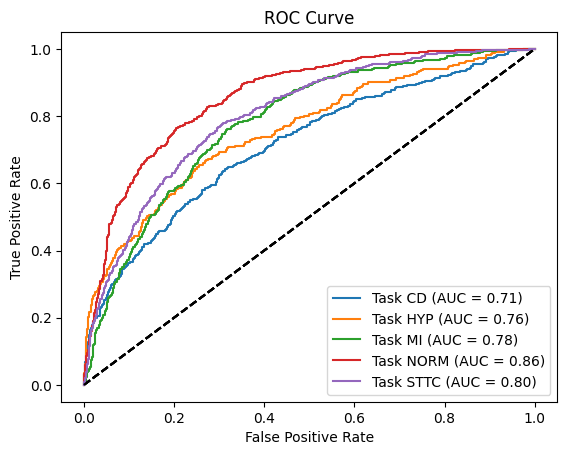

In [34]:
# Get the ROC AUC score for each task
from sklearn.metrics import roc_auc_score, roc_curve

roc_auc_scores = []
# Get the targets and predictions for the task
# iterate over the test set to get the predictions
preds = []
targets = []
for x, metadata, y in datamodule.test_dataloader():
    x = torch.cat((x, metadata), dim=2)
    y_hat = model(x.float())
    preds.append(torch.sigmoid(y_hat).cpu().detach().numpy())
    targets.append(y.cpu().detach().numpy())

preds = np.concatenate(preds)
targets = np.concatenate(targets)
print(preds.shape)
for i in range(targets.shape[1]):
    roc_auc = roc_auc_score(targets[:, i], preds[:, i])
    roc_auc_scores.append(roc_auc)
    fpr, tpr, _ = roc_curve(targets[:, i], preds[:, i])
    plt.plot(fpr, tpr, label=f'Task {class_names[i]} (AUC = {roc_auc:.2f})')
    # Add a dashed line where the ROC AUC is 0.5
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()

plt.show()


We can see that the model is able learn the data effectivly and we get decently high ROC scores.

c:\Users\Fran.DESKTOP-VD7PKMI\mambaforge\lib\site-packages\lime\lime_tabular.py:372: UserWarning: 
                    Prediction probabilties do not sum to 1, and
                    thus does not constitute a probability space.
                    Check that you classifier outputs probabilities
                    (Not log probabilities, or actual class predictions).
                    
  warnings.warn("""



Explanation for instance CD:
sex <= -0.95: 0.1098418596185238
-0.56 < age <= 0.10: -0.08592267747948781
-0.23 < heart_axis <= 1.12: 0.03023297310831705
has_infarction_stadium1 <= 0.00: 0.0
has_infarction_stadium2 <= 0.00: 0.0
has_extra_beats <= 0.00: 0.0
has_baseline_drift <= 0.00: 0.0


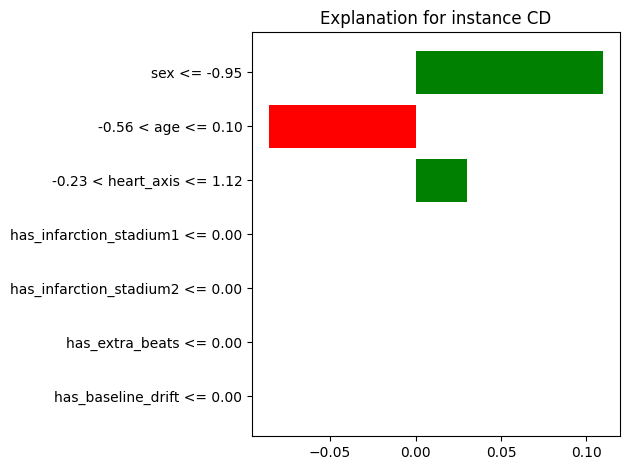

c:\Users\Fran.DESKTOP-VD7PKMI\mambaforge\lib\site-packages\lime\lime_tabular.py:372: UserWarning: 
                    Prediction probabilties do not sum to 1, and
                    thus does not constitute a probability space.
                    Check that you classifier outputs probabilities
                    (Not log probabilities, or actual class predictions).
                    
  warnings.warn("""



Explanation for instance HYP:
sex <= -0.95: 0.11359134184201924
age <= -0.56: 0.03379585175520521
-0.23 < heart_axis <= 1.12: 0.030386924619378673
has_infarction_stadium1 <= 0.00: 0.0
has_infarction_stadium2 <= 0.00: 0.0
has_extra_beats <= 0.00: 0.0
has_baseline_drift <= 0.00: 0.0


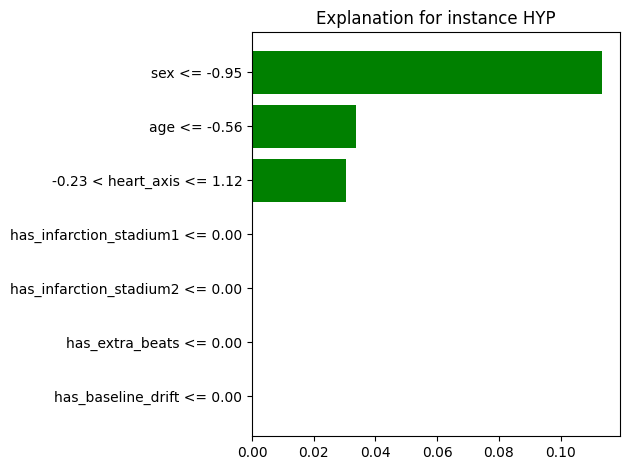

c:\Users\Fran.DESKTOP-VD7PKMI\mambaforge\lib\site-packages\lime\lime_tabular.py:372: UserWarning: 
                    Prediction probabilties do not sum to 1, and
                    thus does not constitute a probability space.
                    Check that you classifier outputs probabilities
                    (Not log probabilities, or actual class predictions).
                    
  warnings.warn("""



Explanation for instance MI:
sex <= -0.95: 0.10074056627179025
-0.56 < age <= 0.10: -0.07969355365753497
heart_axis <= -0.57: 0.030267608204177184
has_infarction_stadium1 <= 0.00: 0.0
has_infarction_stadium2 <= 0.00: 0.0
has_extra_beats <= 0.00: 0.0
has_baseline_drift <= 0.00: 0.0


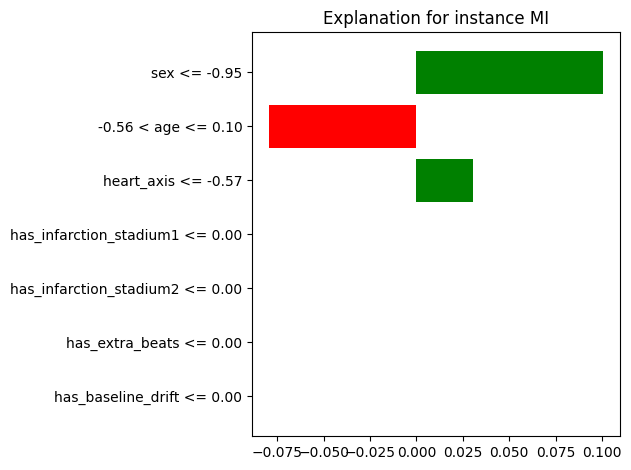

c:\Users\Fran.DESKTOP-VD7PKMI\mambaforge\lib\site-packages\lime\lime_tabular.py:372: UserWarning: 
                    Prediction probabilties do not sum to 1, and
                    thus does not constitute a probability space.
                    Check that you classifier outputs probabilities
                    (Not log probabilities, or actual class predictions).
                    
  warnings.warn("""



Explanation for instance NORM:
sex <= -0.95: 0.11069514633213838
age <= -0.56: 0.033845422881558625
-0.23 < heart_axis <= 1.12: 0.030663553644515056
has_infarction_stadium1 <= 0.00: 0.0
has_infarction_stadium2 <= 0.00: 0.0
has_extra_beats <= 0.00: 0.0
has_baseline_drift <= 0.00: 0.0


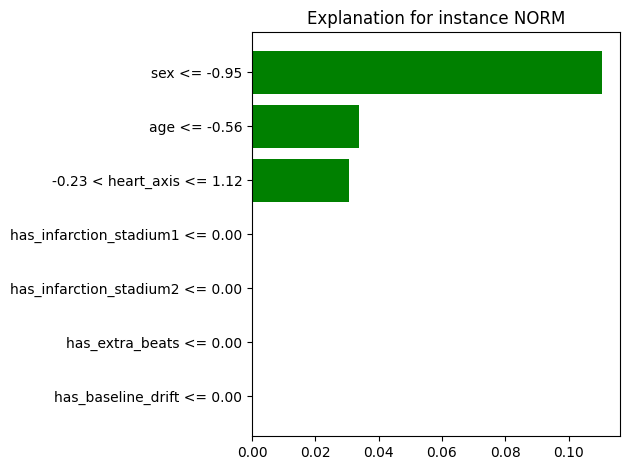

c:\Users\Fran.DESKTOP-VD7PKMI\mambaforge\lib\site-packages\lime\lime_tabular.py:372: UserWarning: 
                    Prediction probabilties do not sum to 1, and
                    thus does not constitute a probability space.
                    Check that you classifier outputs probabilities
                    (Not log probabilities, or actual class predictions).
                    
  warnings.warn("""



Explanation for instance STTC:
sex <= -0.95: 0.10918265872397702
-0.56 < age <= 0.10: -0.08879823833228616
-0.23 < heart_axis <= 1.12: 0.032857320902396556
has_infarction_stadium1 <= 0.00: 0.0
has_infarction_stadium2 <= 0.00: 0.0
has_extra_beats <= 0.00: 0.0
has_baseline_drift <= 0.00: 0.0


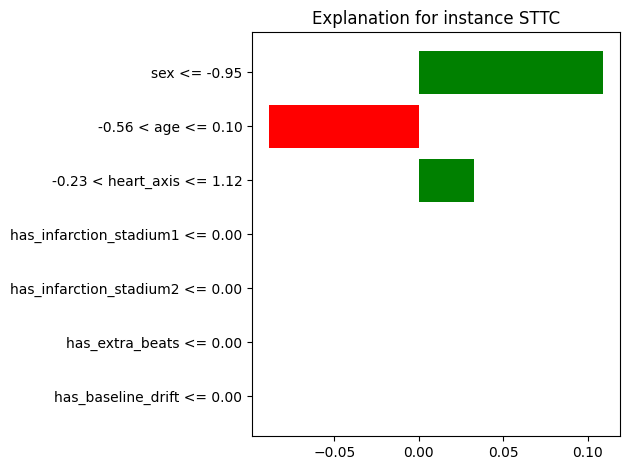

In [35]:
import numpy as np
import torch
from lime import lime_tabular
from sklearn.preprocessing import StandardScaler

# Assuming you have your trained model and test dataset available

# Function to get model predictions
def predict_fn(X):
    model.eval()
    with torch.no_grad():
        X_tensor = torch.tensor(X, dtype=torch.float32)
        # Assuming your model expects both ECG and metadata
        # You might need to adjust this part based on your exact model input
        dummy_ecg = torch.zeros((X.shape[0], 1000, 12))  # Adjust dimensions as needed
        X_combined = torch.cat((dummy_ecg, X_tensor.unsqueeze(1).repeat(1, 1000, 1)), dim=2)
        outputs = model(X_combined)
        probs = torch.sigmoid(outputs).numpy()
    return probs

# Prepare the feature names
feature_names = ['age', 'heart_axis', 'has_infarction_stadium1', 'has_infarction_stadium2', 
                 'has_extra_beats', 'has_baseline_drift', 'sex']

# Create the LIME explainer
explainer = lime_tabular.LimeTabularExplainer(
    datamodule.train_dataset.x_metadata.numpy()[:, 0, :],  # Use only one time step of metadata
    feature_names=feature_names,
    class_names=list(class_names),
    mode='classification'
)

# Get explanations for a few test instances
num_explanations = 5
for i in range(num_explanations):
    # Get a test instance
    instance = datamodule.test_dataset.x_metadata[i, 0, :].numpy()
    
    # Get the explanation
    exp = explainer.explain_instance(instance, predict_fn, num_features=len(feature_names))
    
    # Print the explanation
    print(f"\nExplanation for instance {class_names[i]}:")
    for feature, importance in exp.as_list():
        print(f"{feature}: {importance}")
    
    # Visualize the explanation
    exp.as_pyplot_figure()
    plt.tight_layout()
    plt.title(f"Explanation for instance {class_names[i]}")
    plt.show()

We can see that the infraction beats and drifts dont seem to have a big impact on the classification task, so we might consider removing them from the model.

### Final Conclusions

This model has been succesful, but there are many things that could be improved upon.

Also other architectures such as CNNs, and ResNets should be tested as well.

As well as other techniques such as self supervised learning, and transfer learning.